**Assignment**

1. Remember to add your name to the title of the notebook
2. The goal is to explore models that underfit and overfit, and to deal with overfitting by using the techniques seen in class.


In [155]:
# Import needed libraries
import numpy as np
import sys, os, pdb
import pandas as pd
from matplotlib import pyplot as plt
import keras


Data:

Consists of the gene expression profile of several cells (coming from a patient).

There is a train and a test datasets already provided to you.

They are organized as a matrix of cells x genes.

Given a cell, the goal is to predict the correct cell-type based on the genes' expressions for that sample.

In [156]:
# Link your Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [157]:
# Load data

# Path to source batch
train_path = "/content/drive/MyDrive/DEEP LEARNING NOTEBOOKS/Homework 2: ShallowNN & Regularization/train.pkl"
# Path to target batch
test_path = "/content/drive/MyDrive/DEEP LEARNING NOTEBOOKS/Homework 2: ShallowNN & Regularization/test.pkl"
# Column containing cell-types
lname = "labels"

train_batch = pd.read_pickle(train_path)
test_batch = pd.read_pickle(test_path)

In [158]:
train_batch

index,HES4,ISG15,TNFRSF18,TNFRSF4,MMP23B,UTS2,TNFRSF9,RBP7,PGD,AGTRAP,...,AP000692.10,BACE2,MX1,AP001059.6,AIRE,COL6A2,S100B,MT-ATP8,MT-ND6,labels
index,,,,,,,,,,,,,,,,,,,,,
data_3p-AAACCTGAGCATCATC-0,-0.196407,2.163650,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,-0.410718,-0.578313,-0.609471,...,-0.100605,-0.169544,3.396856,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,B cell
data_3p-AAACCTGAGCTAGTGG-0,-0.196407,1.371853,-0.186414,8.028668,-0.130663,-0.079505,-0.089647,-0.410718,1.221355,-0.609471,...,-0.100605,-0.169544,-0.382577,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,CD4 T cell
data_3p-AAACCTGCACATTAGC-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,-0.410718,1.770606,-0.609471,...,-0.100605,-0.169544,-0.382577,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,0.840558,CD4 T cell
data_3p-AAACCTGCACTGTTAG-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,2.437211,-0.578313,1.062532,...,-0.100605,-0.169544,-0.382577,8.922243,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,Monocyte_CD14
data_3p-AAACCTGCATAGTAAG-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,1.606579,-0.578313,1.112563,...,-0.100605,-0.169544,-0.382577,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,Monocyte_CD14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
data_3p-TTTGTCATCATGTCCC-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,-0.410718,-0.578313,-0.609471,...,-0.100605,-0.169544,-0.382577,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,CD8 T cell
data_3p-TTTGTCATCCGATATG-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,-0.410718,-0.578313,-0.609471,...,-0.100605,-0.169544,2.025987,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,0.335671,CD8 T cell
data_3p-TTTGTCATCGTCTGAA-0,-0.196407,-0.564395,-0.186414,-0.222519,-0.130663,-0.079505,-0.089647,1.252710,0.921344,-0.609471,...,-0.100605,-0.169544,-0.382577,-0.099155,-0.064381,-0.186117,-0.077992,-0.931465,-0.777325,Monocyte_CD14


In [159]:
# Extract the common genes so that we can use the same network for both batches

common_genes = list(set(train_batch.columns).intersection(set(test_batch.columns)))
common_genes.sort()
train_batch = train_batch[list(common_genes)]
test_batch = test_batch[list(common_genes)]

train_mat = train_batch.drop(lname, axis=1)
train_labels = train_batch[lname]

test_mat = test_batch.drop(lname, axis=1)
test_labels = test_batch[lname]

# values are already normalized (ignore this)
mat = train_mat.values
mat_round = np.rint(mat)
error = np.mean(np.abs(mat - mat_round))
print(train_mat.shape, test_mat.shape)
print(train_labels.value_counts())

(8098, 1199) (7378, 1199)
labels
CD4 T cell                     2267
CD8 T cell                     2076
Monocyte_CD14                  1914
B cell                         1199
NK cell                         303
Monocyte_FCGR3A                 206
Plasmacytoid dendritic cell      67
Megakaryocyte                    49
Hematopoietic stem cell          17
Name: count, dtype: int64


In [160]:
train_labels.unique()

['B cell', 'CD4 T cell', 'Monocyte_CD14', 'CD8 T cell', 'Monocyte_FCGR3A', 'NK cell', 'Megakaryocyte', 'Plasmacytoid dendritic cell', 'Hematopoietic stem cell']
Categories (9, object): ['B cell', 'CD4 T cell', 'CD8 T cell', 'Hematopoietic stem cell', ...,
                         'Monocyte_CD14', 'Monocyte_FCGR3A', 'NK cell',
                         'Plasmacytoid dendritic cell']

Q1: What type of problem are you dealing with?
- We are dealing with multi-class classification problem. Each cell belongs to exactly one of 9 cell types, and the model has to predict which one..

Q2: What is the size of the input, i.e., number of features?
- The input size is 1199, one input per gene (feature)
Q3: How many neurons should you have in the last layer?
- 9 neurons, one for each cell type

Q4: What is the most appropiate activation function to use in the last layer?
- Softmax: gives us a probability between 0 and 1, and all 9 output neurons add up to 1, therefore it is a probability distribution where we can pick one as the best.
Why not ReLU (no upper limit; the outputs aren't probabilities), and
Why not sigmoid (each output is independent, so the outputs don't sum to 1; sigmoid suits multi-label problems).

In [161]:
 # Labels: process them to be in an adequate format
from keras.utils import to_categorical
class_names = sorted(train_labels.unique())
name_to_id = {name: i for i, name in enumerate(class_names)} #name to number

# Replace each string label with its number
y_train_int = train_labels.map(name_to_id).values
y_test_int  = test_labels.map(name_to_id).values

#number to one-hot vector of length 9
y_train = to_categorical(y_train_int, num_classes=9)
y_test  = to_categorical(y_test_int,  num_classes=9)

# 5. Inputs as NumPy arrays (like x_train in the classwork)
x_train = train_mat.values
x_test  = test_mat.values



Q5: How did you modify the labels?
- Since networks cannot work with strings, i first converted each of the cell types into a number from 0 to 8, replacing every label. With to_categorical, we implemented on_hot encoding with a vector of 9 values, all 0s except for 1 in the index of the class.

Q6: Which loss function to use:
Since it is a multi-class classification problem, we are going to use a crossentropy loss function. Since we have N classes (9) and the labels are one-hot encoded, we use categorical_crossentropy. It compares the 9 softmax probabilities with the one-hot label and computes -log(p) of the probability given to the correct class: the loss is small when the network is confident and right, and large when it is confident and wrong.

Things I would like to see (at least):

- Without using any kind of regularization, train 3 networks: one that underfits the data, one that does OK, and one that overfits very easily.
-- Comment on why you think each network behaves in a specific way: e.g., number of parameters, number of layers, size of each layer...
-- Comment on the results you observe

- Deal with overfitting by using:
-- L1, L2 or combination of both
-- Dropout
-- Comment on the results: what works better, how you chose the regularization parameter or dropout rate, etc.

- Show the results on the test set of your "best" model.

- Provide some conclusions of the analysis you performed.


## Function to plot

In [162]:
import matplotlib.pyplot as plt
def plot_history(history, title):
    h = history.history
    ep = range(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h['loss'], 'bo', label='Train'); ax[0].plot(ep, h['val_loss'], 'b', label='Val')
    ax[0].set_title(f'{title}: loss'); ax[0].legend()
    ax[1].plot(ep, h['accuracy'], 'bo', label='Train'); ax[1].plot(ep, h['val_accuracy'], 'b', label='Val')
    ax[1].set_title(f'{title}: accuracy'); ax[1].legend()
    plt.show()

In [163]:
keras.utils.set_random_seed(42)

# 1: Underfitting model

- In this model we will train an underfitting predictor. This will be done with two hidden layers with 2 neurons each. Having only 2 neurons, it is a small model which will inturn not learn the patterns good enough.

In [164]:
from tensorflow import keras
from tensorflow.keras import layers

underfit_model = keras.Sequential([
    keras.Input(shape=(1199,)),
    layers.Dense(1, activation="relu"),
    layers.Dense(9, activation="softmax")
])

In [165]:
underfit_model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [166]:
underfit_model.summary()

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_64 (Dense)                │ (None, 1)              │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 9)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,218 (4.76 KB)

 Trainable params: 1,218 (4.76 KB)

 Non-trainable params: 0 (0.00 B)

In [167]:
history_underfit = underfit_model.fit(
    x_train, y_train,
    epochs=100,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3132 - loss: 2.0073 - val_accuracy: 0.3944 - val_loss: 1.9255
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3907 - loss: 1.8887 - val_accuracy: 0.4000 - val_loss: 1.8589
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3935 - loss: 1.8310 - val_accuracy: 0.4025 - val_loss: 1.8137
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3932 - loss: 1.7883 - val_accuracy: 0.4037 - val_loss: 1.7775
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3941 - loss: 1.7522 - val_accuracy: 0.4093 - val_loss: 1.7442
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3919 - loss: 1.7189 - val_accuracy: 0.4093 - val_loss: 1.7122
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3926 - loss: 1.6871 - val_accuracy: 0.4080 - val_loss: 1.6813
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3930 - loss: 1.6564 - val_accuracy: 0.4080 - 

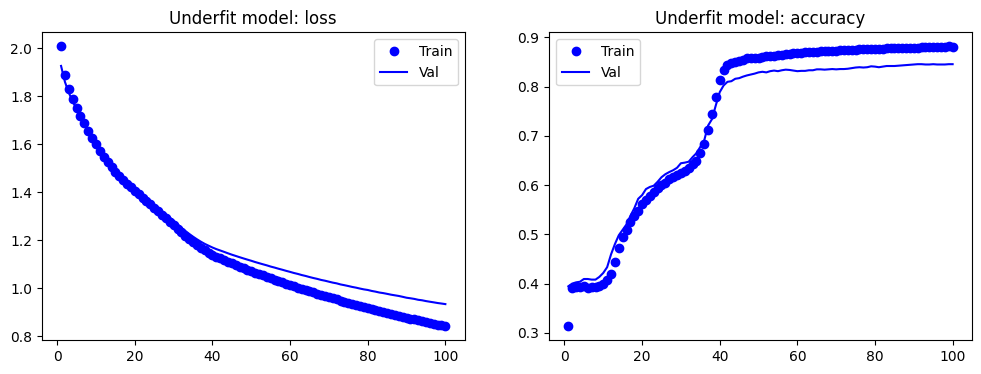

In [168]:
plot_history(history_underfit, "Underfit model")

**Observations:** After 100 epochs the model reaches only 88% training accuracy and 85% validation accuracy, with both losses still high (0.84 train / 0.96 val). Accuracy has flattened, and the loss is only creeping down by a few thousandths per epoch, so more training would bring small gains. Training and validation performance are both poor and fairly close together.

**Why:** With a single hidden neuron, all 1,199 gene expressions are compressed into one number before the model has to separate 9 cell types. Each cell type is squeezed onto a single line, so many of them overlap and can't be told apart. The model lacks the capacity to represent the differences between classes, which is underfitting: high bias, not lack of data.

**Note:** An earlier version with 2 neurons per layer gave very different results depending on the random seed (71% vs. 90% validation accuracy). With so few ReLU units, if one "dies" during training (gets stuck outputting 0), the model effectively loses half its capacity. Interestingly, the 71% run matches this 1-neuron model almost exactly, which supports that explanation. Very small networks are unstable as well as limited.

# 2: OK Fitting model
-

In [169]:
from tensorflow import keras
from tensorflow.keras import layers

#starting the model
ok_model = keras.Sequential([keras.Input(shape=(1199,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(9, activation="softmax")
])


In [170]:
ok_model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [171]:
ok_model.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_66 (Dense)                │ (None, 16)             │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 9)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,625 (76.66 KB)

 Trainable params: 19,625 (76.66 KB)

 Non-trainable params: 0 (0.00 B)

In [172]:
history_ok = ok_model.fit(
    x_train, y_train,
    epochs=20,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6334 - loss: 1.1801 - val_accuracy: 0.8667 - val_loss: 0.5986
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8980 - loss: 0.4255 - val_accuracy: 0.9031 - val_loss: 0.3329
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9336 - loss: 0.2399 - val_accuracy: 0.9420 - val_loss: 0.2195
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9631 - loss: 0.1557 - val_accuracy: 0.9562 - val_loss: 0.1651
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9721 - loss: 0.1099 - val_accuracy: 0.9630 - val_loss: 0.1378
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9799 - loss: 0.0809 - val_accuracy: 0.9691 - val_loss: 0.1172
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9843 - loss: 0.0620 - val_accuracy: 0.9716 - val_loss: 0.1008
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9903 - loss: 0.0470 - val_accuracy: 0.9741 - v

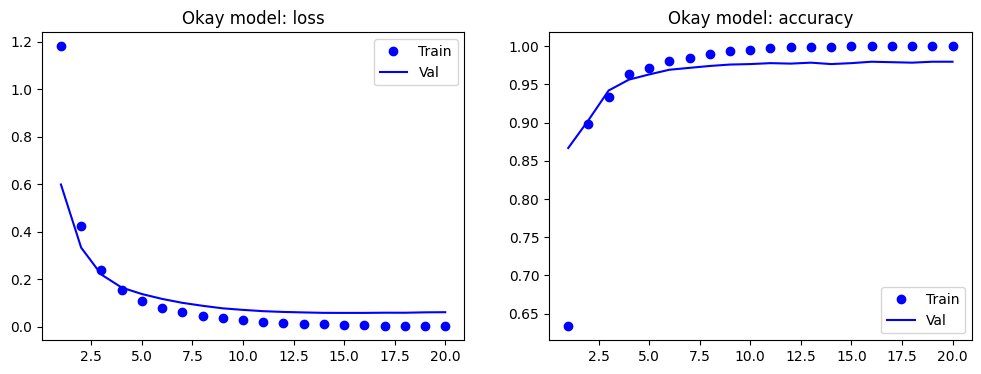

In [173]:
plot_history(history_ok, "Okay model")

**Observations:** The model learns quickly, reaching 97% validation accuracy by epoch 8 and 98% by the end. Validation loss bottoms out around epoch 16 at a very low value and then stays roughly flat, while training accuracy reaches 100%.

**Why:** With 16 neurons per layer, the model learns the gene patterns that difference the cell types, but not so much that it memorizes the training set right away. A small gap between training and validation loss appears in the last epochs, an early sign that longer training would start to overfit. The best stopping point is around epoch 14–16.

# 3: Overfitting model

In [174]:
overfit_model = keras.Sequential([keras.Input(shape=(1199,)),
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(9, activation="softmax")
])

In [175]:
overfit_model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [176]:
overfit_model.summary()

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_69 (Dense)                │ (None, 512)            │       614,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_70 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 9)              │         4,617 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 881,673 (3.36 MB)

 Trainable params: 881,673 (3.36 MB)

 Non-trainable params: 0 (0.00 B)

In [177]:
history_overfit = overfit_model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=512,
    validation_split=0.2
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8358 - loss: 0.6276 - val_accuracy: 0.9735 - val_loss: 0.1069
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9450 - loss: 0.1512 - val_accuracy: 0.9747 - val_loss: 0.0761
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9832 - loss: 0.0510 - val_accuracy: 0.9753 - val_loss: 0.0678
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9940 - loss: 0.0230 - val_accuracy: 0.8772 - val_loss: 0.3851
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9734 - loss: 0.0868 - val_accuracy: 0.9753 - val_loss: 0.0605
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 1.0000 - loss: 0.0066 - val_accuracy: 0.9759 - val_loss: 0.0583
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.9765 - val_loss: 0.0581
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.9772 - v

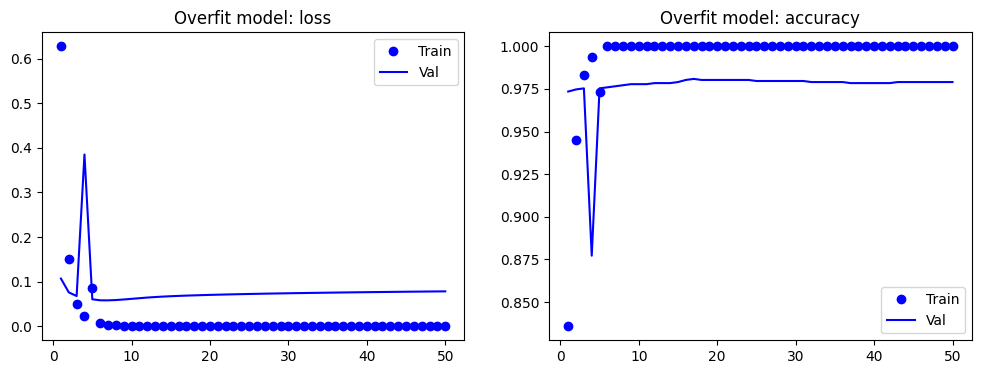

In [178]:
plot_history(history_overfit, "Overfit model")

**Observations:** Training loss drops almost to zero and training accuracy reaches 100% within a few epochs. Validation loss reaches its minimum at epoch 2 or 3 and then rises steadily. The gap between the curves keeps widening.

**Why:** With three layers of 512 neurons, the model has far more parameters than there are training cells, so it can memorize individual cells and not learn general patterns.

Interestingly, validation accuracy stays high at around 98% while validation loss rises. The model still predicts most cells correctly, but it becomes overconfident on the ones it gets wrong, assigning near-zero probability to the true class. Loss detects overfitting earlier than accuracy does.

# 4: Comparisons

In [179]:
def summarize(name, model, history):
    h = history.history
    best = int(np.argmin(h['val_loss']))
    return {'Model': name,
            'Params': model.count_params(),
            'Best val loss': h['val_loss'][best],
            'Best epoch': best + 1,
            'Final train acc': h['accuracy'][-1],
            'Final val acc': h['val_accuracy'][-1],
            'Final loss gap (val-train)': h['val_loss'][-1] - h['loss'][-1]}

comp = pd.DataFrame([
    summarize('Underfit', underfit_model, history_underfit),
    summarize('OK', ok_model, history_ok),
    summarize('Overfit', overfit_model, history_overfit),
]).set_index('Model')

(comp.style
    .background_gradient(subset=['Params'], cmap='Blues')
    .background_gradient(subset=['Final train acc', 'Final val acc'], cmap='Greens')
    .background_gradient(subset=['Best val loss', 'Final loss gap (val-train)'], cmap='Reds')
    .format({'Params': '{:,}', 'Best val loss': '{:.4f}',
             'Final train acc': '{:.2%}', 'Final val acc': '{:.2%}',
             'Final loss gap (val-train)': '{:.4f}'}))

,Params,Best val loss,Best epoch,Final train acc,Final val acc,Final loss gap (val-train)
Model,,,,,,
Underfit,"1,218",0.9339,100,88.16%,84.57%,0.0923
OK,"19,625",0.0583,15,99.98%,97.96%,0.0592
Overfit,"881,673",0.0581,7,100.00%,97.90%,0.0783


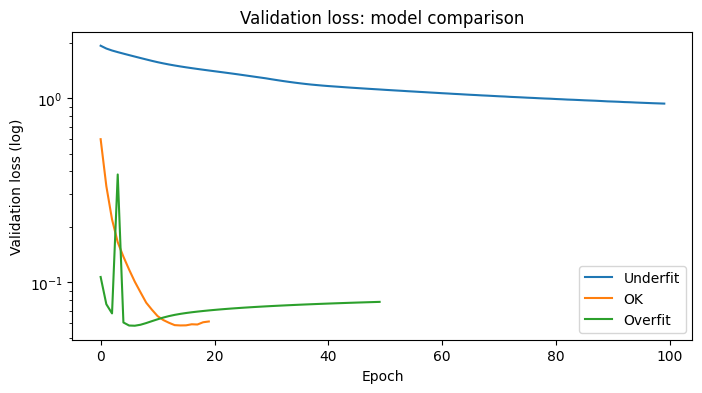

In [180]:
plt.figure(figsize=(8, 4))
for name, hist in [('Underfit', history_underfit), ('OK', history_ok), ('Overfit', history_overfit)]:
    plt.plot(hist.history['val_loss'], label=name)
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('Validation loss (log)')
plt.title('Validation loss: model comparison'); plt.legend(); plt.show()

**Conclusions:**

- **Underfit (1,218 params):** By far the worst model, with ~85% validation accuracy and a validation loss (0.93) about 16× higher than the other two. Its loss is still slowly decreasing at epoch 100, but at this rate it would never catch up. The model is simply too small.
- **OK vs. Overfit:** Both reach almost the same best validation loss (~0.058) and ~98% validation accuracy, even though the overfit model has ~45× more parameters. Extra capacity did not buy better performance.
- **The difference is in how they behave over time:** The overfit model reaches its best point much faster (epoch 7 vs. 15), but then its validation loss climbs steadily while training accuracy sits at 100%. It is memorizing the training data. It also shows an unstable spike around epoch 3, typical of very large networks.
- **Takeaway:** For this dataset, a moderate model is enough. A large model can match it only if it is stopped at the right time or regularized, which motivates the next section.

# 5: Regularization

In [181]:
from tensorflow.keras import regularizers

def build_model(reg=None, dropout=0.0):
    keras.utils.set_random_seed(42)  # same starting point for every experiment
    model = keras.Sequential([keras.Input(shape=(1199,))])
    for _ in range(2):
        model.add(layers.Dense(512, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(9, activation="softmax"))
    model.compile(optimizer='rmsprop', loss='categorical_crossentropy',
                  metrics=['accuracy', keras.metrics.CategoricalCrossentropy(name='ce')])
    return model

In [182]:
experiments = {
    'L2 1e-4': dict(reg=regularizers.l2(1e-4)),
    'L2 1e-3': dict(reg=regularizers.l2(1e-3)),
    'L2 1e-2': dict(reg=regularizers.l2(1e-2)),
    'L1 1e-5': dict(reg=regularizers.l1(1e-5)),
    'L1 1e-4': dict(reg=regularizers.l1(1e-4)),
    'L1 1e-3': dict(reg=regularizers.l1(1e-3)),
    'L1+L2 1e-4': dict(reg=regularizers.l1_l2(l1=1e-4, l2=1e-4)),
    'Dropout 0.2': dict(dropout=0.2),
    'Dropout 0.3': dict(dropout=0.3),
    'Dropout 0.5': dict(dropout=0.5),
}

reg_histories, reg_models = {}, {}
for name, kw in experiments.items():
    print(f'Training {name}...')
    m = build_model(**kw)
    reg_histories[name] = m.fit(x_train, y_train, epochs=50, batch_size=512,
                                validation_split=0.2, verbose=0)
    reg_models[name] = m

Training L2 1e-4...
Training L2 1e-3...
Training L2 1e-2...
Training L1 1e-5...
Training L1 1e-4...
Training L1 1e-3...
Training L1+L2 1e-4...
Training Dropout 0.2...
Training Dropout 0.3...
Training Dropout 0.5...


In [183]:
rows = []
for name, hist in reg_histories.items():
    h = hist.history
    best = int(np.argmin(h['val_ce']))
    rows.append({'Model': name,
                 'Best val CE': h['val_ce'][best],
                 'Best epoch': best + 1,
                 'Final val CE': h['val_ce'][-1],
                 'Rise after best': h['val_ce'][-1] - h['val_ce'][best],
                 'Final train acc': h['accuracy'][-1],
                 'Final val acc': h['val_accuracy'][-1]})
reg_table = pd.DataFrame(rows).set_index('Model')

(reg_table.style
    .background_gradient(subset=['Best val CE', 'Final val CE', 'Rise after best'], cmap='Reds')
    .background_gradient(subset=['Final train acc', 'Final val acc'], cmap='Greens')
    .format({'Best val CE': '{:.4f}', 'Final val CE': '{:.4f}', 'Rise after best': '{:.4f}',
             'Final train acc': '{:.2%}', 'Final val acc': '{:.2%}'}))

,Best val CE,Best epoch,Final val CE,Rise after best,Final train acc,Final val acc
Model,,,,,,
L2 1e-4,0.0628,6,0.0760,0.0132,100.00%,97.84%
L2 1e-3,0.0583,31,0.0611,0.0028,100.00%,98.21%
L2 1e-2,0.0581,41,0.0599,0.0018,98.58%,98.09%
L1 1e-5,0.0627,6,0.0761,0.0134,100.00%,98.09%
L1 1e-4,0.0564,29,0.0690,0.0126,100.00%,97.78%
L1 1e-3,0.0649,31,0.0722,0.0073,99.80%,98.02%
L1+L2 1e-4,0.0578,25,0.0697,0.0119,99.09%,97.84%
Dropout 0.2,0.0561,5,0.0966,0.0405,100.00%,98.09%
Dropout 0.3,0.0592,4,0.0972,0.0380,100.00%,98.09%


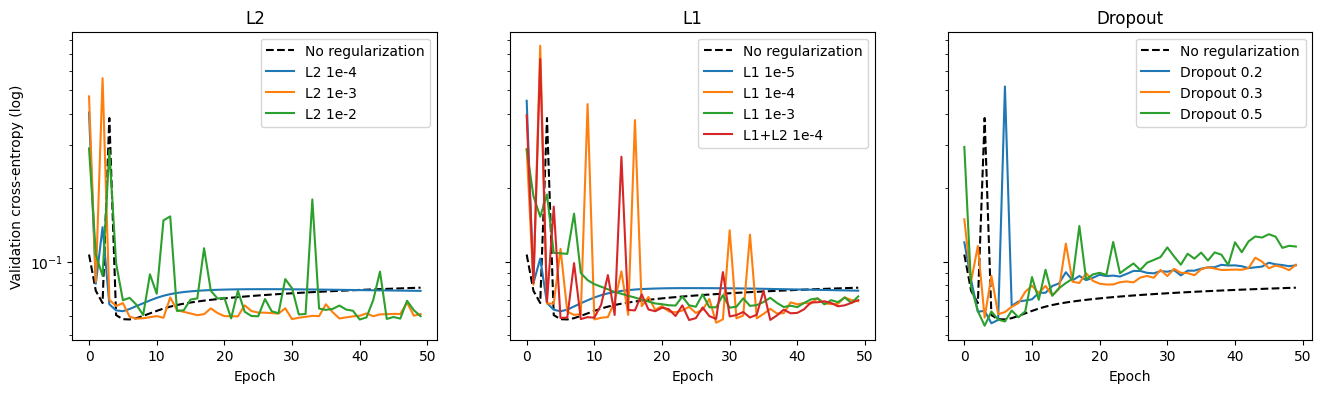

In [184]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, prefix in zip(ax, ['L2', 'L1', 'Dropout']):
    a.plot(history_overfit.history['val_loss'], 'k--', label='No regularization')
    for name, hist in reg_histories.items():
        if name.startswith(prefix):
            a.plot(hist.history['val_ce'], label=name)
    a.set_title(prefix); a.set_xlabel('Epoch'); a.set_yscale('log'); a.legend()
ax[0].set_ylabel('Validation cross-entropy (log)')
plt.show()

**Regularization results:**

We kept the overfit architecture (2 × 512 neurons) and tried L2, L1, L1+L2, and dropout, using a small grid of values for each. To compare fairly, we tracked validation cross-entropy separately, since the L1/L2 penalty is added to Keras' reported loss. We chose values by looking for a low best validation error and, above all, a small rise after the best epoch (i.e. no overfitting over time).

- **L2** worked best. At λ = 1e-3 and 1e-2, validation error stays almost flat after its minimum (rise of 0.003 and 0.002, vs. ~0.02 without regularization). At 1e-2, training accuracy stays below 100%, showing the model no longer memorizes the training set. λ = 1e-4 was too weak to make a difference.
- **L1** reduced overfitting less effectively. At 1e-3 it started to hurt learning (higher best validation error), a sign of too strong a penalty.
- **Dropout** achieved the lowest best validation error (0.0548 at rate 0.5), but only around epoch 4. Afterwards validation error rose even more than in the unregularized model. Dropout improves the best point but would need early stopping to be useful on its own.
- Validation accuracy was very similar for all models (97.8–98.2%, a difference of only a few cells), so cross-entropy was the more informative metric.

**Selected model:** L2 with λ = 1e-2, the most stable model with the lowest final validation error and ~98% validation accuracy.

# 6: Test set

Test accuracy: 97.13% | Test cross-entropy: 0.1123
                             precision    recall  f1-score   support

                     B cell      0.990     0.994     0.992      1172
                 CD4 T cell      0.979     0.967     0.973      2183
                 CD8 T cell      0.933     0.960     0.946      1066
    Hematopoietic stem cell      1.000     0.857     0.923         7
              Megakaryocyte      1.000     0.789     0.882        57
              Monocyte_CD14      0.979     0.982     0.980      2176
            Monocyte_FCGR3A      0.979     0.904     0.940       355
                    NK cell      0.983     0.993     0.988       290
Plasmacytoid dendritic cell      0.750     1.000     0.857        72

                   accuracy                          0.971      7378
                  macro avg      0.955     0.938     0.942      7378
               weighted avg      0.972     0.971     0.971      7378



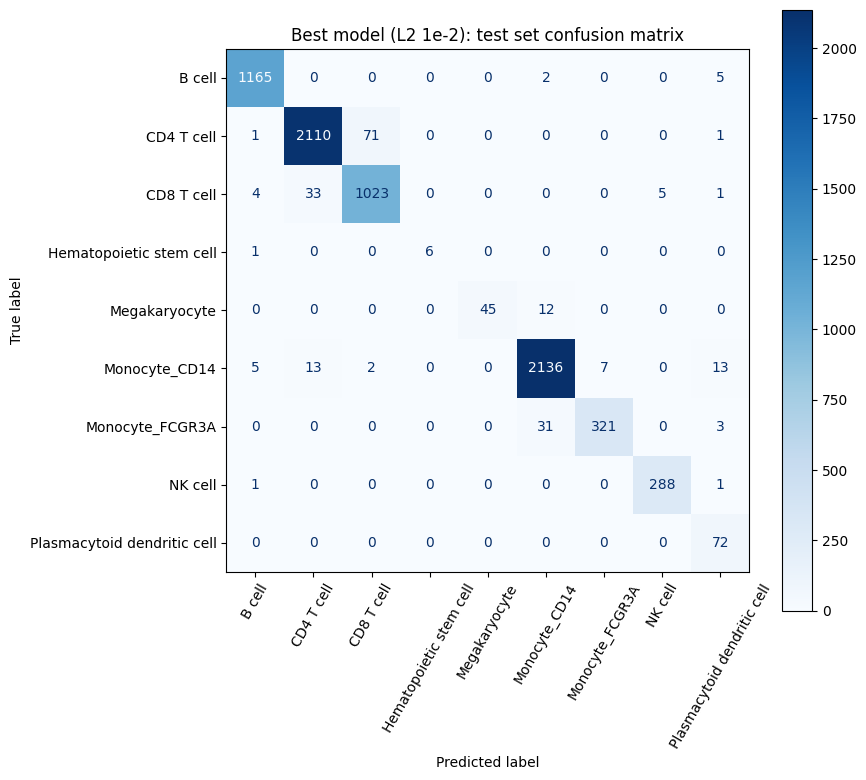

In [185]:
best_model = reg_models['L2 1e-2']

test_loss, test_acc, test_ce = best_model.evaluate(x_test, y_test, verbose=0)
print(f'Test accuracy: {test_acc:.2%} | Test cross-entropy: {test_ce:.4f}')

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
y_pred = best_model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test_int, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test_int, y_pred),
                       display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=60)
plt.title('Best model (L2 1e-2): test set confusion matrix'); plt.tight_layout(); plt.show()